<a href="https://colab.research.google.com/github/Khadeeja-beevi12/Data-Visualization/blob/main/Assignment_03_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

titanic = sns.load_dataset("titanic")

print("First five rows of the Titanic dataset:")
display(titanic.head())

print("Dataset shape:", titanic.shape)

print("\nDataset information:")
titanic.info()

print("\nMissing values:")
print(titanic.isnull().sum())


First five rows of the Titanic dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Dataset shape: (891, 15)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Missing values:
survived       

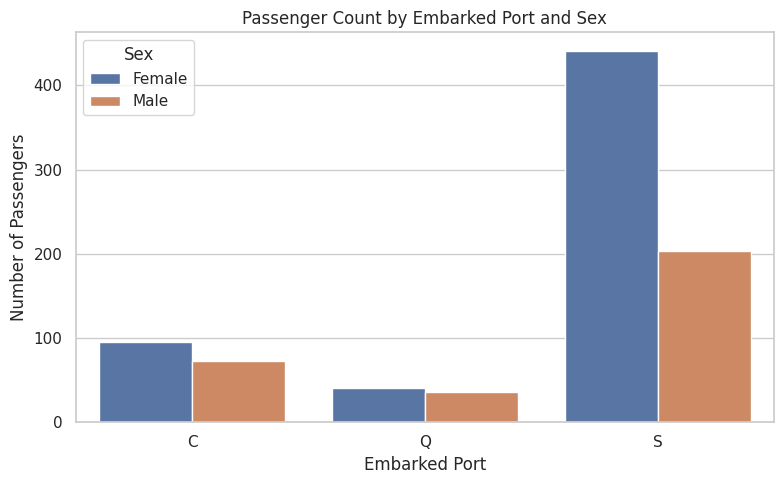

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=titanic,
    x="embarked",
    hue="sex",
    order=["C", "Q", "S"]
)

plt.title("Passenger Count by Embarked Port and Sex")
plt.xlabel("Embarked Port")
plt.ylabel("Number of Passengers")
plt.legend(title="Sex", labels=["Female", "Male"])
plt.tight_layout()
plt.show()


 Southampton (S) had the highest number of passengers, followed by Cherbourg (C) and Queenstown (Q). Male passengers outnumbered female passengers at Southampton and Queenstown. At Cherbourg, the numbers of male and female passengers were more balanced.

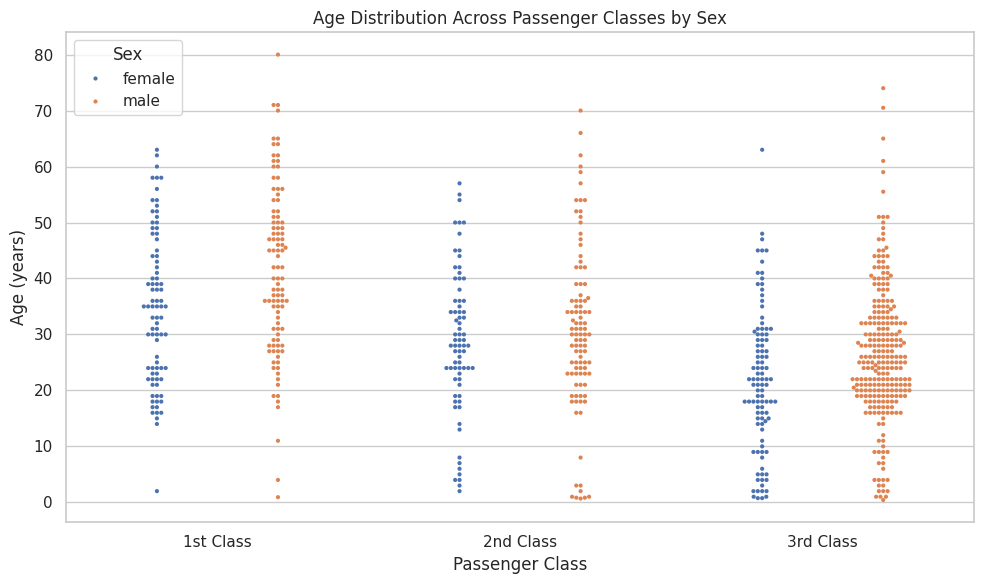

In [5]:
plt.figure(figsize=(10, 6))

sns.swarmplot(
    data=titanic.dropna(subset=["age", "sex", "pclass"]),
    x="pclass",
    y="age",
    hue="sex",
    dodge=True,
    size=3
)

plt.title("Age Distribution Across Passenger Classes by Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Age (years)")
plt.xticks([0, 1, 2], ["1st Class", "2nd Class", "3rd Class"])
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


Passengers of different ages travelled in all three classes. Children were present in every class, while the age distributions extended into adulthood and old age. The plot shows differences in the distribution of male and female passengers within each class.

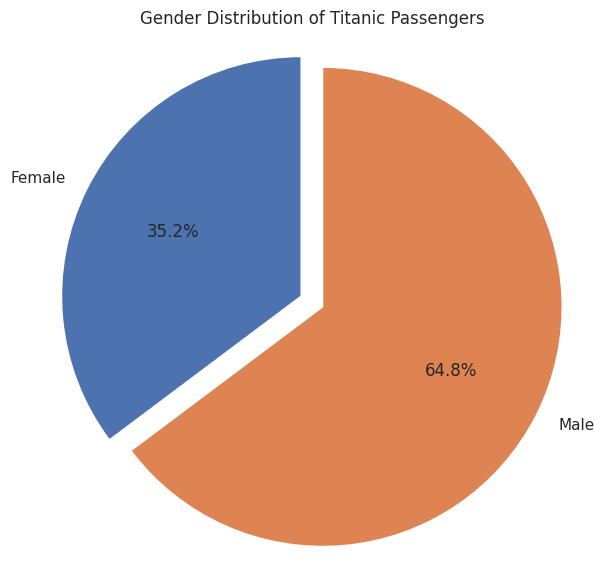

In [7]:
gender_counts = titanic["sex"].value_counts().reindex(
    ["female", "male"]
)

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=["Female", "Male"],
    autopct="%1.1f%%",
    explode=(0.1, 0),
    startangle=90,
    shadow=False
)

plt.title("Gender Distribution of Titanic Passengers")
plt.axis("equal")
plt.show()


Male passengers represented a larger proportion of the Titanic dataset than female passengers. The pie chart clearly shows the difference in gender distribution, with the female slice highlighted using the explode parameter.

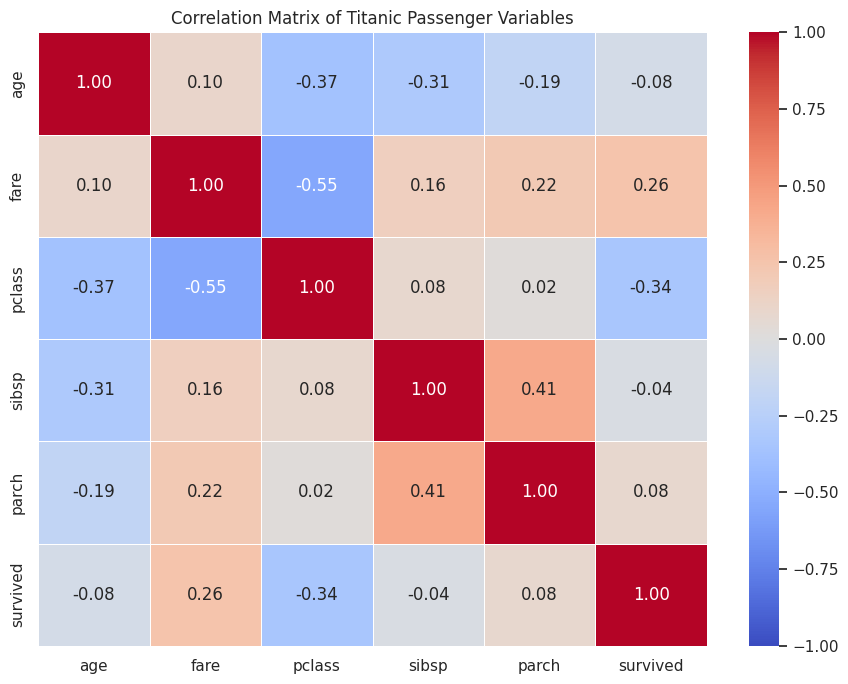

In [8]:
columns = ["age", "fare", "pclass", "sibsp", "parch", "survived"]

correlation_matrix = titanic[columns].corr()

# Create the heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Matrix of Titanic Passenger Variables")
plt.tight_layout()
plt.show()


 Passenger class and fare show a negative correlation because lower class numbers generally correspond to higher fares. Fare has a positive correlation with survival, while passenger class has a negative correlation with survival. These associations do not establish causation. The remaining relationships vary in strength.

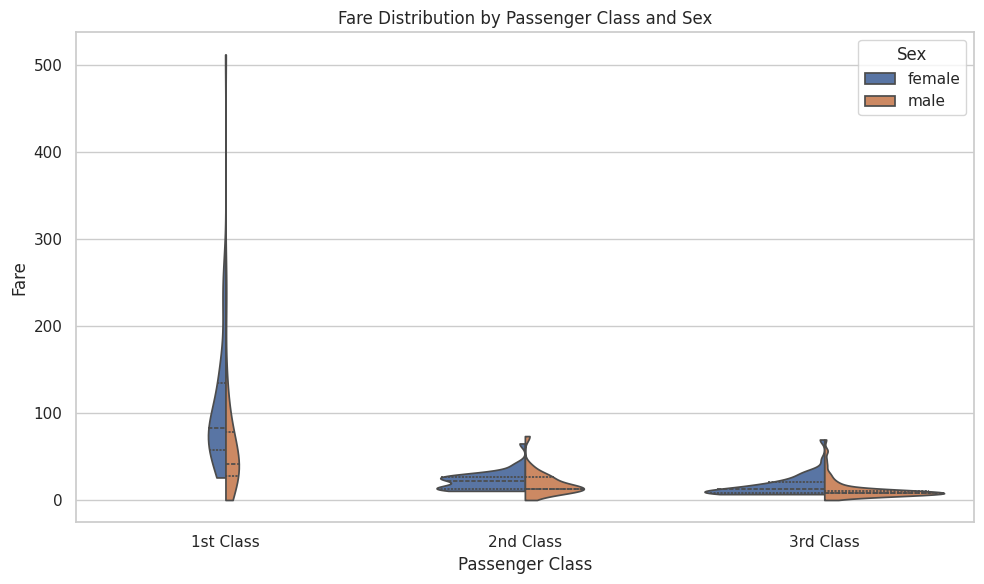

In [9]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=titanic.dropna(subset=["fare", "pclass", "sex"]),
    x="pclass",
    y="fare",
    hue="sex",
    split=True,
    inner="quart",
    cut=0
)

plt.title("Fare Distribution by Passenger Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.xticks([0, 1, 2], ["1st Class", "2nd Class", "3rd Class"])
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


 First-class passengers generally paid higher fares and showed a wider fare distribution than passengers in second and third class. The distributions for male and female passengers overlap, but the fare patterns vary across classes. A small number of expensive tickets can produce long or asymmetric fare distributions.

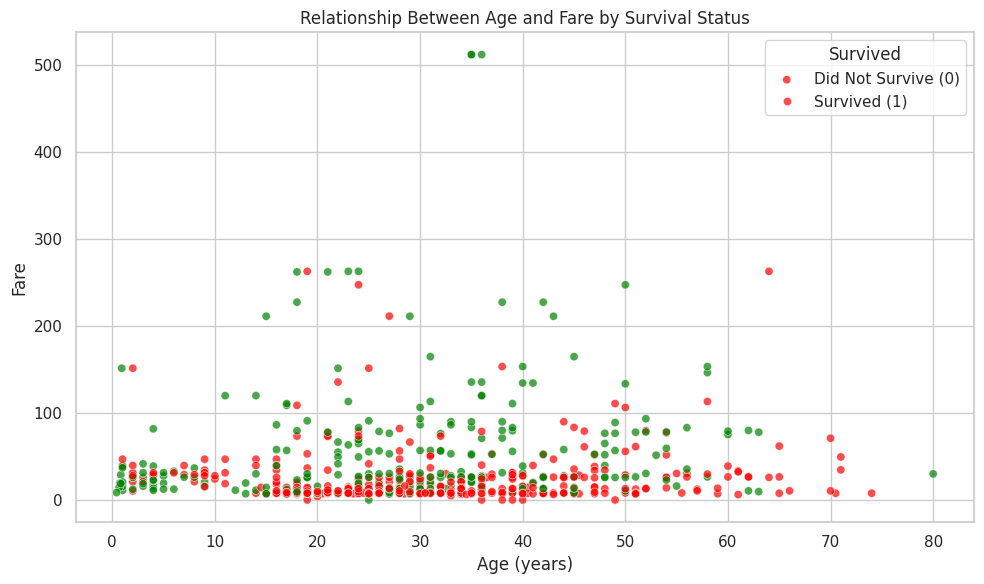

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=titanic.dropna(subset=["age", "fare", "survived"]),
    x="age",
    y="fare",
    hue="survived",
    palette={0: "red", 1: "green"},
    alpha=0.7
)

plt.title("Relationship Between Age and Fare by Survival Status")
plt.xlabel("Age (years)")
plt.ylabel("Fare")
plt.legend(
    title="Survived",
    labels=["Did Not Survive (0)", "Survived (1)"]
)
plt.tight_layout()
plt.show()


The scatter plot shows that passengers of different ages paid a wide range of fares. Both survivors and non-survivors appear across several age and fare ranges. The plot suggests that age and fare alone do not fully explain survival, although fare and passenger class are associated with survival outcomes.